# 7주차 분석 (CPU) — LightGBM few-shot · LoRA 결과 채점

- **7-5 LightGBM 곡선**: GPU 불필요 → 이 노트북에서 바로 실행
- **7-3 · 7-4 · 7-5 TSFM 채점·그래프**: 서버에서 `wk07_LoRA.ipynb` 실행 후 `results/wk7/`(preds·fit_log·7-1 CSV)를 받아 실행

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

ROOT = Path("..").resolve()
sys.path.append(str(ROOT))
from src.backtest import rolling_backtest
from src.metrics import compute_naive_denominators, score_backtest
from src import bench_models as bm, finetune as ft

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

OUT = ROOT / "results/wk7"
PRED_DIR = OUT / "preds"
OUT.mkdir(parents=True, exist_ok=True)
CONTEXT, STEP_SIZE, N_WINDOWS = 1024, 168, 52  # 5주차·GPU 노트북과 동일

data = bm.load_data()
mask = ft.load_anomaly_mask(data.columns)

def mase_by_building(res):
    denom = compute_naive_denominators(data, train_end=data.index.get_loc(res["timestamp"].min()), season=168)
    return score_backtest(res, denom)[0].set_index("building")["MASE"]

## 과제 7-1. CPU vs GPU — 서버에서 저장한 CSV로 다시 그리기

5주차 대비 MASE 최대 차이: 2.2e-08 | 예측값 최대 차이: 0.0052
device            cpu   cuda  GPU 배속
24h zero-shot   47.16   4.75    9.94
24h +외기온        69.65  10.26    6.79
168h zero-shot  38.05   2.58   14.75
168h +외기온       73.28   5.85   12.52
                      cpu  cuda  노트북 cpu (5주차)  GPU 배속(서버 cpu 대비)
입력                                                               
건물 1개 (5주차 5-6 조건)  134.1  11.6          341.8               11.5
건물 17개 배치           662.7  38.6            NaN               17.2


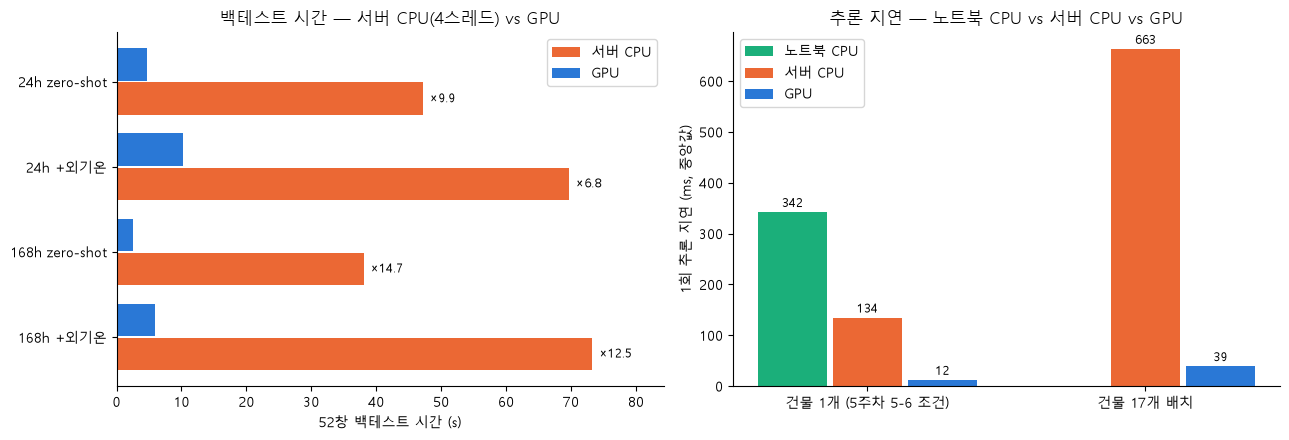

In [2]:
COLORS = {"노트북 CPU": "#1baf7a", "서버 CPU": "#eb6834", "GPU": "#2a78d6"}  # 장치별 고정 색 (두 그래프 공통)

rep = pd.read_csv(OUT / "gpu_reproduction.csv")
print(f"5주차 대비 MASE 최대 차이: {(rep['MASE_평균'] - rep['5주차 MASE(노트북 CPU)']).abs().max():.1e} "
      f"| 예측값 최대 차이: {rep['예측값 최대 차이'].max():.4f}")
bt = rep.pivot_table(index=["horizon", "공변량"], columns="device", values="백테스트 시간(s)")
bt.index = [f"{h}h {'+외기온' if c else 'zero-shot'}" for h, c in bt.index]
bt["GPU 배속"] = bt["cpu"] / bt["cuda"]
lat = pd.read_csv(OUT / "latency_cpu_vs_gpu.csv").set_index("입력").iloc[::-1]
print(bt.round(2).to_string())
print(lat.round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax, y = axes[0], np.arange(len(bt))
for off, col, name in [(0.2, "cpu", "서버 CPU"), (-0.2, "cuda", "GPU")]:
    ax.barh(y + off, bt[col], height=0.38, color=COLORS[name], label=name)
for i, (cpu, sp) in enumerate(zip(bt["cpu"], bt["GPU 배속"])):
    ax.text(cpu + 1, i + 0.2, f"×{sp:.1f}", va="center", fontsize=9)
ax.set_yticks(y, bt.index)
ax.invert_yaxis()
ax.set_xlabel("52창 백테스트 시간 (s)")
ax.set_title("백테스트 시간 — 서버 CPU(4스레드) vs GPU")
ax.set_xlim(0, bt["cpu"].max() * 1.15)
ax.legend(loc="upper right")

ax, x = axes[1], np.arange(len(lat))
for off, col, name in [(-0.27, "노트북 cpu (5주차)", "노트북 CPU"), (0, "cpu", "서버 CPU"), (0.27, "cuda", "GPU")]:
    bars = ax.bar(x + off, lat[col], width=0.25, color=COLORS[name], label=name)
    ax.bar_label(bars, fmt="%.0f", fontsize=9, padding=2)
ax.set_xticks(x, lat.index)
ax.set_ylabel("1회 추론 지연 (ms, 중앙값)")
ax.set_title("추론 지연 — 노트북 CPU vs 서버 CPU vs GPU")
ax.legend()
for a in axes:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(OUT / "cpu_vs_gpu_summary.png", dpi=110)
plt.show()

## 과제 7-5 (LightGBM). few-shot 효율 곡선 — GPU 불필요

In [3]:
def lgb_fixed_fns(train_df):
    # 학습은 train_df 로 1회만, 예측은 각 창의 이력(lag)을 그대로 사용 — TSFM 파인튜닝과 같은 조건
    model_fn, predict_fn = bm.make_global_fns(24)
    fitted = model_fn(train_df)
    return (lambda hist: {**fitted, "train_df": hist}), predict_fn

rows = []
for f in ft.FRACTIONS:
    train_df = ft.finetune_frame(data, mask, f)
    res = rolling_backtest(data, *lgb_fixed_fns(train_df), n_windows=N_WINDOWS, horizon=24,
                           train_mode="expanding", step_size=STEP_SIZE)
    rows += [{"학습 비율": f, "학습 시점 수": len(train_df), "building": b, "MASE": v}
             for b, v in mase_by_building(res).items()]

lgb_curve = pd.DataFrame(rows)
lgb_curve.to_csv(OUT / "lgb_fewshot_per_building.csv", index=False, encoding="utf-8")
lgb_summary = lgb_curve.groupby(["학습 비율", "학습 시점 수"])["MASE"].agg(["mean", "std"]).reset_index()
lgb_summary["학습 기간(일)"] = lgb_summary["학습 시점 수"] / 24
print(lgb_summary.round(4).to_string(index=False))
wk3 = pd.read_csv(ROOT / "results/wk3/global_model_summary.csv")
print(f"참고 — 3주차 LightGBM Global 24h (창마다 재학습·전체 이력): {wk3.loc[wk3['horizon'] == 24, 'MASE_평균'].item():.4f}")

 학습 비율  학습 시점 수   mean    std  학습 기간(일)
  0.01       88 1.9053 2.1790    3.6667
  0.05      439 1.2124 0.4770   18.2917
  0.10      878 0.9505 0.6999   36.5833
  0.50     4392 0.7699 0.3231  183.0000
  1.00     8784 0.7028 0.2257  366.0000
참고 — 3주차 LightGBM Global 24h (창마다 재학습·전체 이력): 0.6211


---
## 여기부터는 GPU 결과가 필요합니다
서버에서 `wk07_LoRA.ipynb`를 끝까지 실행한 뒤 `results/wk7/`를 받아 오면 실행하세요.

In [4]:
def run_mase(prefix):
    # seed 별 건물 MASE → (건물 × seed) 표
    return pd.DataFrame({s: mase_by_building(pd.read_parquet(PRED_DIR / f"{prefix}_s{s}.parquet")) for s in ft.SEEDS})

zero = {h: mase_by_building(pd.read_csv(OUT / f"chronos_{h}h_zero_cuda.csv", parse_dates=["timestamp"])) for h in [24, 168]}
fit_log = pd.read_csv(OUT / "fit_log.csv")

## 과제 7-3. LoRA 파인튜닝 — zero-shot 대비 개선율 · 학습 파라미터 · VRAM

 horizon  zero-shot MASE  LoRA MASE (seed 평균)  seed 간 표준편차  개선율(%) 개선 건물 수  Wilcoxon p (건물 짝)
      24          0.3837               0.3904       0.0017 -1.7367    5/17              0.011
     168          0.8100               0.7908       0.0016  2.3698   17/17              0.000

           학습 파라미터      전체 파라미터  학습 비율(%)  최대 VRAM(GB)  학습 시간(s)
horizon                                                         
24       1206912.0  120684576.0       1.0        4.671   250.344
168      1206912.0  120684576.0       1.0        5.070   287.383


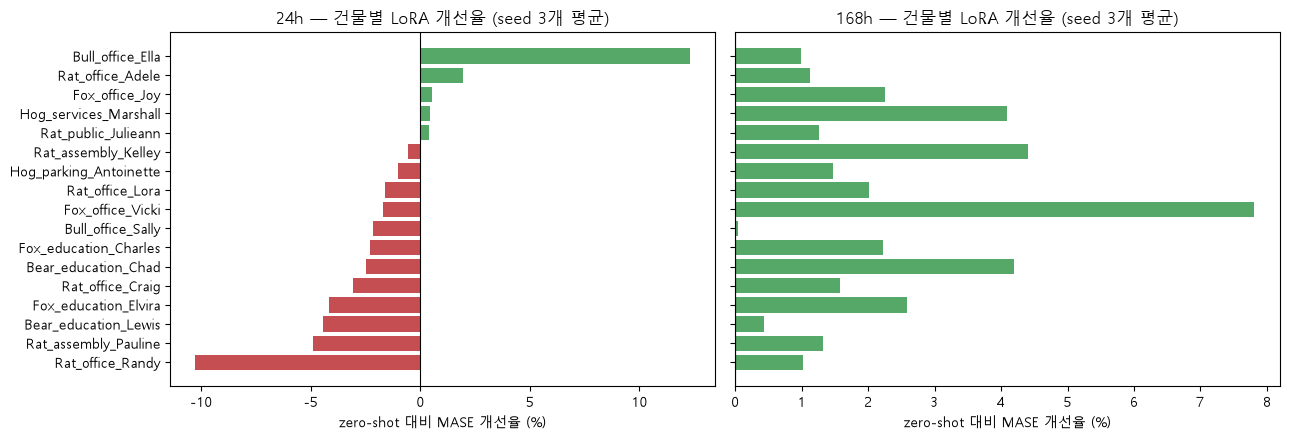

In [5]:
rows, per_building = [], {}
for h in [24, 168]:
    lora = run_mase(f"clean_{h}h_f100")
    pair = pd.concat([zero[h].rename("zero"), lora.mean(axis=1).rename("lora")], axis=1).dropna()
    per_building[h] = (pair["zero"] - pair["lora"]) / pair["zero"] * 100
    rows.append({"horizon": h, "zero-shot MASE": zero[h].mean(), "LoRA MASE (seed 평균)": lora.mean().mean(),
                 "seed 간 표준편차": lora.mean().std(),
                 "개선율(%)": (zero[h].mean() - lora.mean().mean()) / zero[h].mean() * 100,
                 "개선 건물 수": f"{(pair['lora'] < pair['zero']).sum()}/{len(pair)}",
                 "Wilcoxon p (건물 짝)": wilcoxon(pair["zero"], pair["lora"]).pvalue})
lora_summary = pd.DataFrame(rows)
lora_summary.to_csv(OUT / "lora_summary.csv", index=False, encoding="utf-8")
print(lora_summary.round(4).to_string(index=False))

cost = (fit_log[fit_log["run"].str.match(r"clean_\d+h_f100")]
        .groupby("horizon")[["학습 파라미터", "전체 파라미터", "학습 비율(%)", "최대 VRAM(GB)", "학습 시간(s)"]].mean())
cost.to_csv(OUT / "lora_cost.csv", encoding="utf-8")
print()
print(cost.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, h in zip(axes, [24, 168]):
    s = per_building[h].sort_values()
    ax.barh(s.index, s, color=np.where(s > 0, "#55A868", "#C44E52"))
    ax.axvline(0, color="k", lw=0.8)
    ax.set_title(f"{h}h — 건물별 LoRA 개선율 (seed 3개 평균)")
    ax.set_xlabel("zero-shot 대비 MASE 개선율 (%)")
plt.tight_layout()
plt.savefig(OUT / "lora_per_building.png", dpi=110)
plt.show()

## 과제 7-4. 오염 학습 대조 실험 — 예측 성능 · 잔차 분포

                 zero-shot  정상학습 LoRA  오염학습 LoRA
2017 MASE (24h)     0.3837     0.3904     0.3913
seed 간 표준편차            NaN     0.0017     0.0020



                 모델  정상구간 정규화잔차  이상구간 정규화잔차  이상/정상 비율
          zero-shot       0.992       5.642     5.689
          정상학습 LoRA       1.000       5.800     5.800
          오염학습 LoRA       1.000       5.791     5.790
LightGBM 정상학습 (4주차)       1.000       7.235     7.235
LightGBM 오염학습 (4주차)       0.847       2.043     2.412
※ 이상/정상 비율이 클수록 잔차 기반 탐지가 쉬움. 4주차와 정규화 기준 모델이 달라 절대값보다 비율로 비교


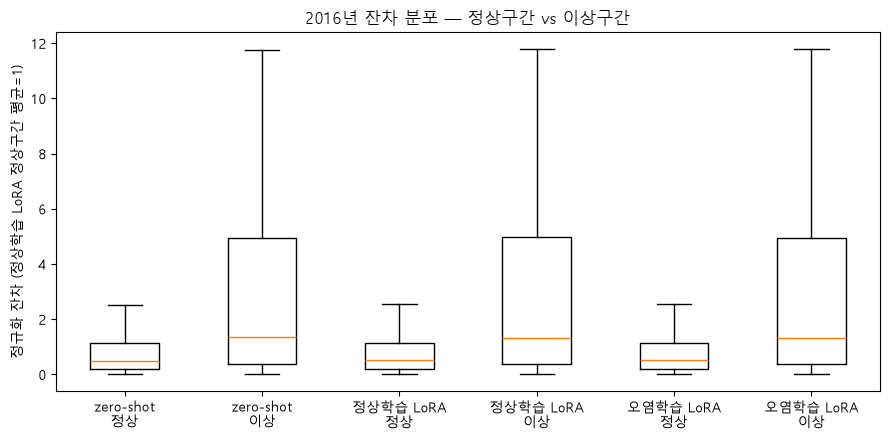

In [6]:
cont = run_mase("cont_24h_f100")
clean = run_mase("clean_24h_f100")
perf = pd.DataFrame({"zero-shot": [zero[24].mean(), np.nan],
                     "정상학습 LoRA": [clean.mean().mean(), clean.mean().std()],
                     "오염학습 LoRA": [cont.mean().mean(), cont.mean().std()]},
                    index=["2017 MASE (24h)", "seed 간 표준편차"])
perf.to_csv(OUT / "contamination_performance.csv", encoding="utf-8")
print(perf.round(4).to_string())

# 2016년 잔차: 4주차 과제 4-3(연간 전체)와 같은 정규화 — 정상학습 모델의 건물별 정상구간 평균 잔차 = 1
lab = mask.stack().rename("is_anomaly").rename_axis(["timestamp", "building"]).reset_index()
res16 = {}
for name, f in {"zero-shot": "zero_24h_2016", "정상학습 LoRA": "clean_24h_f100_s0_2016",
                "오염학습 LoRA": "cont_24h_f100_s0_2016"}.items():
    r = pd.read_parquet(PRED_DIR / f"{f}.parquet").merge(lab, on=["timestamp", "building"], how="inner")
    res16[name] = r.dropna(subset=["y_true", "y_pred"]).assign(resid=lambda d: (d["y_true"] - d["y_pred"]).abs())
norm = res16["정상학습 LoRA"].query("~is_anomaly").groupby("building")["resid"].mean()
for r in res16.values():
    r["resid_norm"] = r["resid"] / r["building"].map(norm)

resid_summary = pd.DataFrame([{"모델": k, "정상구간 정규화잔차": r.loc[~r["is_anomaly"], "resid_norm"].mean(),
                               "이상구간 정규화잔차": r.loc[r["is_anomaly"], "resid_norm"].mean()} for k, r in res16.items()])
wk4 = pd.read_csv(ROOT / "results/wk4/residual_summary_full_year.csv").assign(모델=lambda d: "LightGBM " + d["모델"] + " (4주차)")
resid_summary = pd.concat([resid_summary, wk4], ignore_index=True)
resid_summary["이상/정상 비율"] = resid_summary["이상구간 정규화잔차"] / resid_summary["정상구간 정규화잔차"]
resid_summary.to_csv(OUT / "contamination_residuals.csv", index=False, encoding="utf-8")
print()
print(resid_summary.round(3).to_string(index=False))
print("※ 이상/정상 비율이 클수록 잔차 기반 탐지가 쉬움. 4주차와 정규화 기준 모델이 달라 절대값보다 비율로 비교")

fig, ax = plt.subplots(figsize=(9, 4.5))
box = [r.loc[r["is_anomaly"] == a, "resid_norm"].dropna() for r in res16.values() for a in (False, True)]
ax.boxplot(box, showfliers=False)
ax.set_xticks(range(1, 7), [f"{k}\n{'이상' if a else '정상'}" for k in res16 for a in (False, True)])
ax.set_ylabel("정규화 잔차 (정상학습 LoRA 정상구간 평균=1)")
ax.set_title("2016년 잔차 분포 — 정상구간 vs 이상구간")
plt.tight_layout()
plt.savefig(OUT / "contamination_residuals.png", dpi=110)
plt.show()

## 과제 7-5. few-shot 효율 곡선 — TSFM vs LightGBM · 손익분기점

         TSFM  TSFM_std  LightGBM  학습 기간(일)
학습 비율                                      
0.01   0.4181    0.0029    1.9053    3.6667
0.05   0.4143    0.0015    1.2124   18.2917
0.10   0.3993    0.0046    0.9505   36.5833
0.50   0.3923    0.0007    0.7699  183.0000
1.00   0.3904    0.0017    0.7028  366.0000

손익분기점 없음 — TSFM이 전 구간 우위


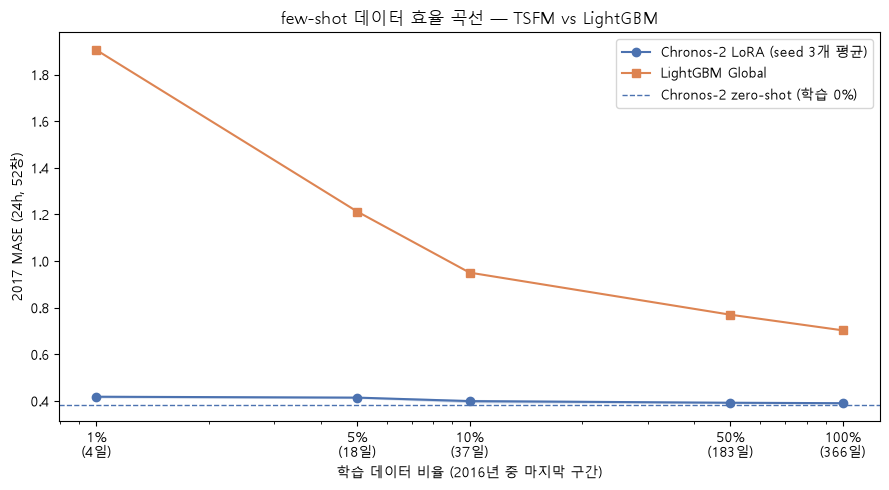

In [7]:
tsfm = pd.DataFrame({f: run_mase(f"clean_24h_f{round(f * 100):03d}").mean() for f in ft.FRACTIONS})  # seed × 비율
curve = pd.DataFrame({"TSFM": tsfm.mean(), "TSFM_std": tsfm.std(),
                      "LightGBM": lgb_curve.groupby("학습 비율")["MASE"].mean()})
curve["학습 기간(일)"] = lgb_curve.groupby("학습 비율")["학습 시점 수"].first() / 24
curve.index.name = "학습 비율"

# 손익분기점: TSFM 우위(LightGBM - TSFM > 0)가 처음 뒤집히는 구간을 log(비율)에서 선형 보간
diff, x = curve["LightGBM"] - curve["TSFM"], np.log10(curve.index.to_numpy())
cross = [10 ** (x[i] - diff.iloc[i] * (x[i + 1] - x[i]) / (diff.iloc[i + 1] - diff.iloc[i]))
         for i in range(len(diff) - 1) if diff.iloc[i] > 0 >= diff.iloc[i + 1]]
curve.to_csv(OUT / "fewshot_curve.csv", encoding="utf-8")
print(curve.round(4).to_string())
if cross:
    days = cross[0] * len(ft.finetune_frame(data)) / 24
    print(f"\n손익분기점 ≈ {cross[0]:.1%} (약 {days:.0f}일 ≈ {days / 30.4:.1f}개월). 이보다 이력이 짧으면 TSFM 유리")
else:
    print("\n손익분기점 없음 — " + ("TSFM이 전 구간 우위" if (diff > 0).all() else "LightGBM이 전 구간 우위이거나 교차가 반대 방향"))

fig, ax = plt.subplots(figsize=(9, 5))
pct = curve.index * 100
ax.plot(pct, curve["TSFM"], "o-", color="#4C72B0", label="Chronos-2 LoRA (seed 3개 평균)")
ax.fill_between(pct, curve["TSFM"] - curve["TSFM_std"], curve["TSFM"] + curve["TSFM_std"], color="#4C72B0", alpha=0.2)
ax.plot(pct, curve["LightGBM"], "s-", color="#DD8452", label="LightGBM Global")
ax.axhline(zero[24].mean(), color="#4C72B0", ls="--", lw=1, label="Chronos-2 zero-shot (학습 0%)")
for c in cross:
    ax.axvline(c * 100, color="gray", ls=":", label=f"손익분기점 ≈ {c:.1%}")
ax.set_xscale("log")
ax.set_xticks(pct, [f"{p:g}%\n({d:.0f}일)" for p, d in zip(pct, curve["학습 기간(일)"])])
ax.set_xlabel("학습 데이터 비율 (2016년 중 마지막 구간)")
ax.set_ylabel("2017 MASE (24h, 52창)")
ax.set_title("few-shot 데이터 효율 곡선 — TSFM vs LightGBM")
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "fewshot_curve.png", dpi=110)
plt.show()